# Exploring the MEF income data

First look at the **IRPEF incomes per comune** published by the Ministry of Economy and Finance
(tax years 2014 and 2024). The goal is to understand the data before writing the loading and
cleaning code of the `affordability` package.

1. Download and load the data
2. Checks: columns, missing values, duplicates, comuni that changed
3. Average taxable income
4. First charts for one comune
5. Three economic insights: inequality, effective tax rate, income mix

The final analysis is in `analysis.ipynb`; this notebook is exploration only.

In [1]:
import io
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

In [2]:
# The notebook runs from notebooks/, so the project root is one level up.
# (In a .py module we will use Path(__file__).resolve().parent instead.)
base_dir = Path.cwd().parent

In [3]:
CODE_COL = "Codice Istat Comune"
PROVINCE_COL = "Sigla Provincia"
NAME_COL = "Denominazione Comune"
TAXPAYERS_COL = "Numero contribuenti"
TAXABLE_FREQ_COL = "Reddito imponibile - Frequenza"
TAXABLE_AMOUNT_COL = "Reddito imponibile - Ammontare"
MILAN_CODE = "015146"

## 1. Download and load the MEF income data

In [4]:
# Only the year changes in the MEF download link, so we keep one template
# and fill in the year with .format(year=...). No long URL is repeated.
MEF_URL_TEMPLATE = (
    "https://www1.finanze.gov.it/finanze/analisi_stat/public/v_4_0_0/contenuti/"
    "Redditi_e_principali_variabili_IRPEF_su_base_comunale_CSV_{year}.zip?d=1615465800"
)

INCOME_YEARS = [2014, 2024]

mef_raw_data_dir = base_dir / "data" / "raw" / "mef"

# Create the 'data/raw/mef' directory if it doesn't already exist
mef_raw_data_dir.mkdir(parents=True, exist_ok=True)

# File types we accept from inside the ZIP (a tuple, because endswith() accepts tuples)
extensions = (".csv", ".xlsx", ".xls")

for year in INCOME_YEARS:
    url = MEF_URL_TEMPLATE.format(year=year)

    # Cache: if a file for this year is already on disk, skip the download.
    # mef_raw_data_dir / "..." is already a Path, so no need to wrap it in Path().
    if any((mef_raw_data_dir / f"mef_income_{year}{ext}").exists() for ext in extensions):
        print(f"mef_income_{year} already downloaded, skipping.")
        continue

    print(f"Downloading {year} from {url} ...")
    # timeout=30: give up after 30 seconds instead of freezing forever
    response = requests.get(url, timeout=30)
    # turn HTTP errors (404, 500, ...) into exceptions
    response.raise_for_status()

    # Open the ZIP directly from memory (no temporary .zip file on disk)
    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        # .lower() so that "DATA.CSV" is accepted too, not only "data.csv"
        data_files = [
            info for info in z.infolist()
            if info.filename.lower().endswith(extensions)
        ]

        # We save every file as "mef_income_<year>.<ext>". With two data files
        # in one ZIP, the second would overwrite the first, so we stop and say so.
        if len(data_files) != 1:
            raise ValueError(
                f"Expected 1 data file in the {year} ZIP, found {len(data_files)}: "
                f"{[info.filename for info in data_files]}"
            )

        fileinfo = data_files[0]
        extension = Path(fileinfo.filename).suffix.lower()
        target_path = mef_raw_data_dir / f"mef_income_{year}{extension}"

        # Read the file out of the ZIP and write it to disk
        target_path.write_bytes(z.read(fileinfo.filename))
        print(f"Extracted to: {target_path.relative_to(base_dir)}")

mef_income_2014 already downloaded, skipping.
mef_income_2024 already downloaded, skipping.


In [5]:
mef_dfs = {}
for year in INCOME_YEARS:
    path = mef_raw_data_dir / f"mef_income_{year}.csv"
    print(f"Loading {path.name} ...")
    df = pd.read_csv(
        path,
        sep=";",
        encoding="latin-1",
        dtype={CODE_COL: str},   # keep the leading zero of the ISTAT code
        keep_default_na=False,   # don't treat "NA" as missing: it is Napoli's province code
        na_values=[""],          # only an empty cell is missing
    )
    # The file already has the tax year: check it, then add a short "year" column
    assert (df["Anno di imposta"] == year).all(), f"unexpected tax year in {path.name}"
    df["year"] = year
    mef_dfs[year] = df

Loading mef_income_2014.csv ...
Loading mef_income_2024.csv ...


In [6]:
df2014 = mef_dfs[2014]
df2014.head(10)

,Anno di imposta,Codice catastale,Codice Istat Comune,Denominazione Comune,Sigla Provincia,Regione,Codice Istat Regione,Numero contribuenti,Reddito da fabbricati - Frequenza,Reddito da fabbricati - Ammontare,...,Reddito complessivo da 15000 a 26000 euro - Ammontare,Reddito complessivo da 26000 a 55000 euro - Frequenza,Reddito complessivo da 26000 a 55000 euro - Ammontare,Reddito complessivo da 55000 a 75000 euro - Frequenza,Reddito complessivo da 55000 a 75000 euro - Ammontare,Reddito complessivo da 75000 a 120000 euro - Frequenza,Reddito complessivo da 75000 a 120000 euro - Ammontare,Reddito complessivo oltre 120000 euro - Frequenza,Reddito complessivo oltre 120000 euro - Ammontare,year
0,2014,A001,028001,ABANO TERME,PD,Veneto,5,14173,6977.0,11684674.0,...,98874364,2889.0,101381179.0,399.0,25555498.0,366.0,33642305.0,156.0,30814993.0,2014
1,2014,A004,098001,ABBADIA CERRETO,LO,Lombardia,3,212,89.0,70008.0,...,1669369,35.0,1128384.0,NaN,NaN,0.0,0.0,0.0,0.0,2014
2,2014,A005,097001,ABBADIA LARIANA,LC,Lombardia,3,2384,1187.0,1565868.0,...,17631595,584.0,19953253.0,60.0,3781730.0,43.0,3910776.0,20.0,4110091.0,2014
3,2014,A006,052001,ABBADIA SAN SALVATORE,SI,Toscana,9,4936,2602.0,3327596.0,...,34555118,718.0,24203466.0,56.0,3568341.0,29.0,2605800.0,11.0,1812778.0,2014
4,2014,A007,095001,ABBASANTA,OR,Sardegna,20,1755,853.0,777290.0,...,10090801,411.0,13455623.0,21.0,1363203.0,8.0,726624.0,NaN,NaN,2014
5,2014,A008,068001,ABBATEGGIO,PE,Abruzzo,13,289,122.0,75154.0,...,1570478,26.0,840483.0,NaN,NaN,0.0,0.0,0.0,0.0,2014
6,2014,A010,015002,ABBIATEGRASSO,MI,Lombardia,3,22731,11217.0,17402757.0,...,164513830,5561.0,191169405.0,645.0,40603241.0,408.0,37665279.0,155.0,31363478.0,2014
7,2014,A012,047001,ABETONE,PT,Toscana,9,533,223.0,395804.0,...,3295526,56.0,1756826.0,5.0,328710.0,NaN,NaN,NaN,NaN,2014
8,2014,A013,076001,ABRIOLA,PZ,Basilicata,17,1030,319.0,178759.0,...,4570426,56.0,1865787.0,5.0,334658.0,NaN,NaN,0.0,0.0,2014
9,2014,A014,088001,ACATE,RG,Sicilia,19,6834,2112.0,1554967.0,...,16917451,344.0,11310094.0,21.0,1330499.0,14.0,1329985.0,4.0,604104.0,2014


In [7]:
df2014[NAME_COL].str.contains("Ã").sum()

# Broken accents would look like "Ã¨". The result is zero, so latin-1 is right.
# MEF names are uppercase ASCII; use ISTAT names for display

np.int64(0)

In [8]:
df2014.dtypes

Anno di imposta                                                                                                     int64
Codice catastale                                                                                                      str
Codice Istat Comune                                                                                                   str
Denominazione Comune                                                                                                  str
Sigla Provincia                                                                                                       str
Regione                                                                                                               str
Codice Istat Regione                                                                                                int64
Numero contribuenti                                                                                                 int64
Reddito da fabbricati - 

## 2. Checks

### Same checks on every year + column differences

In [9]:
for year, df in mef_dfs.items():
    print(f"===== {year} =====")
    print("shape:", df.shape)
    print("code column type:", df[CODE_COL].dtype)
    print("example codes:", df[CODE_COL].head(3).tolist())   # leading zero still there?
    # Missing values: only show the columns that have some
    missing = df.isna().sum()
    print("columns with NaN:")
    print(missing[missing > 0].sort_values(ascending=False))
    print()

# Symmetric difference (^): columns that exist in ONE of the two years only
cols_2014 = set(mef_dfs[2014].columns)
cols_2024 = set(mef_dfs[2024].columns)
print("Only in 2014:", sorted(cols_2014 - cols_2024))
print("Only in 2024:", sorted(cols_2024 - cols_2014))

===== 2014 =====
shape: (8049, 49)
code column type: str
example codes: ['028001', '098001', '097001']
columns with NaN:
Reddito complessivo oltre 120000 euro - Ammontare                                                                 2304
Reddito complessivo oltre 120000 euro - Frequenza                                                                 2304
Reddito di spettanza dell'imprenditore in contabilita' ordinaria  (comprensivo dei valori nulli) - Ammontare      1976
Reddito di spettanza dell'imprenditore in contabilita' ordinaria  (comprensivo dei valori nulli) - Frequenza      1976
Reddito complessivo minore di zero euro - Frequenza                                                               1889
Reddito complessivo minore di zero euro - Ammontare                                                               1889
Reddito complessivo da 75000 a 120000 euro - Ammontare                                                            1476
Reddito complessivo da 75000 a 120000 euro - F

### Make the two years comparable

What the checks above showed:
- 2024 says "- Ammontare in euro", 2014 says "- Ammontare" (one even has a trailing space: "oltre 120000 euro - Ammontare ").
- Some names contain double spaces ("partecipazione  (comprensivo...").
- The lowest bracket was renamed: "minore di zero" (2014) became "minore o uguale a zero" (2024). It now also includes people with exactly 0.
- 2024 has a column called " " that is empty in every row: each line of the CSV ends with ";", so pandas sees one extra, empty column.
- The last row of each file has code `0`: taxpayers not assigned to any comune. Real comuni have a 6-digit code.
- "Sigla Provincia" had 92 NaN: Napoli's code is "NA", which pandas reads as missing by default. Already fixed when loading (`keep_default_na=False, na_values=[""]`).

In [10]:
def clean_mef_columns(mdf):
    """
    Give the MEF columns the same names in every year and drop empty columns.

    Parameters
    ----------
    mdf : pandas.DataFrame
        A MEF income table as read from the CSV.

    Returns
    -------
    pandas.DataFrame
        A copy with harmonised column names and without all-empty columns.
    """
    df = mdf.copy()
    # " ".join(name.split()) removes leading/trailing spaces AND turns double
    # spaces into single ones
    df.columns = [" ".join(col.split()) for col in df.columns]
    df.columns = [
        col.replace("- Ammontare in euro", "- Ammontare")
           .replace("minore o uguale a zero", "minore di zero")
        for col in df.columns
    ]
    # Drop columns where every value is missing (the empty " " column)
    return df.dropna(axis=1, how="all")

# Keep only real comuni: their ISTAT code is exactly 6 digits.
# This drops the final "0" row (taxpayers not assigned to any comune).
for year in mef_dfs:
    df = mef_dfs[year]
    is_comune = df[CODE_COL].str.fullmatch(r"\d{6}")
    print(f"{year}: dropping {(~is_comune).sum()} non-comune rows")
    mef_dfs[year] = df[is_comune].copy()

mef_dfs = {year: clean_mef_columns(df) for year, df in mef_dfs.items()}

cols_2014 = set(mef_dfs[2014].columns)
cols_2024 = set(mef_dfs[2024].columns)
print("Only in 2014:", sorted(cols_2014 - cols_2024))
print("Only in 2024:", sorted(cols_2024 - cols_2014))
print("Napoli province rows:", (mef_dfs[2024][PROVINCE_COL] == "NA").sum())   # 92 after the re-read

2014: dropping 1 non-comune rows
2024: dropping 1 non-comune rows
Only in 2014: []
Only in 2024: ['Reddito complessivo - Ammontare', 'Reddito complessivo - Frequenza', 'Trattamento spettante - Ammontare', 'Trattamento spettante - Frequenza']
Napoli province rows: 92


### Is each comune in the file only once?

In [11]:
for year, df in mef_dfs.items():
    unique = df[CODE_COL].is_unique
    print(f"{year}: codes unique = {unique}")
    if not unique:
        # keep=False marks ALL copies of a duplicated code, so we see every one
        duplicates = df[df[CODE_COL].duplicated(keep=False)]
        print(duplicates[[CODE_COL, NAME_COL]].sort_values(CODE_COL))

2014: codes unique = True
2024: codes unique = True


## 3. Average taxable income per comune
mean income = total taxable income / number of people with taxable income

In [12]:
for year, df in mef_dfs.items():
    df["mean_income"] = df[TAXABLE_AMOUNT_COL] / df[TAXABLE_FREQ_COL]

    print(f"===== {year} =====")
    print(df["mean_income"].describe().round(0))

    columns_to_show = [CODE_COL, NAME_COL, TAXPAYERS_COL, "mean_income"]
    print("\n5 lowest:")
    print(df.nsmallest(5, "mean_income")[columns_to_show])
    print("\n5 highest:")
    print(df.nlargest(5, "mean_income")[columns_to_show])
    print("\nMilan:")
    print(df.loc[df[CODE_COL] == MILAN_CODE, columns_to_show])
    print()

# Look at the size of the extreme comuni: are they tiny villages?
# A village with 50 taxpayers can have a strange average because of 1-2 people.

===== 2014 =====
count     8048.0
mean     17145.0
std       3606.0
min       6579.0
25%      14380.0
50%      17281.0
75%      19626.0
max      44514.0
Name: mean_income, dtype: float64

5 lowest:
     Codice Istat Comune Denominazione Comune  Numero contribuenti  \
1877              013062             CAVARGNA                  123   
5680              013233            VAL REZZO                   92   
2519              103027       CURSOLO-ORASSO                   92   
3342              103036                GURRO                  173   
698               095014              BIDONI'                  112   

      mean_income  
1877  6579.230769  
5680  6922.083333  
2519  7309.247059  
3342  7548.794872  
698   7997.807692  

5 highest:
     Codice Istat Comune Denominazione Comune  Numero contribuenti  \
570               015015             BASIGLIO                 5257   
2523              015097               CUSAGO                 2716   
447               018006         BADIA 

### How many comuni disappeared between 2014 and 2024?

In [13]:
codes_2014 = set(mef_dfs[2014][CODE_COL])
codes_2024 = set(mef_dfs[2024][CODE_COL])

print("rows 2014:", len(mef_dfs[2014]))
print("rows 2024:", len(mef_dfs[2024]))
print("codes in 2014 but not in 2024 (merged or renamed):", len(codes_2014 - codes_2024))
print("codes in 2024 but not in 2014 (new comuni):", len(codes_2024 - codes_2014))

# A few examples of comuni that no longer exist
gone = mef_dfs[2014][mef_dfs[2014][CODE_COL].isin(codes_2014 - codes_2024)]
print(gone[[CODE_COL, NAME_COL, PROVINCE_COL]].head(10))

rows 2014: 8048
rows 2024: 7896
codes in 2014 but not in 2024 (merged or renamed): 401
codes in 2024 but not in 2014 (new comuni): 249
    Codice Istat Comune Denominazione Comune Sigla Provincia
7                047001              ABETONE              PT
24               043001          ACQUACANINA              MC
33               075001   ACQUARICA DEL CAPO              LE
57               104001               AGGIUS              OT
94               104003       ALA' DEI SARDI              OT
100              025002       ALANO DI PIAVE              BL
112              018002   ALBAREDO ARNABOLDI              PV
162              001005      ALICE SUPERIORE              TO
173              006006    ALLUVIONI CAMBIO'              AL
215              022004               AMBLAR              TN


### Findings so far

| File | Separator | Encoding | Rows 2014 / 2024 | One row = ... | Key column |
|---|---|---|---|---|---|
| MEF | `;` | latin-1 | 8,048 / 7,896 comuni | one comune in one tax year | Codice Istat Comune (text, 6 digits) |

- Names are uppercase ASCII (`CAVAGLIA'`, German names in dots like `SILANDRO .SCHLANDERS.`): display the ISTAT names instead.
- NaN = value hidden because very few taxpayers (privacy), mostly in small comuni.
- Income measure: **reddito imponibile** (taxable income). It has no NaN and exists in both years; the total *reddito complessivo* exists only in 2024.
- 401 codes of 2014 no longer exist in 2024 and 249 are new: comuni merged into new ones -> code harmonisation in Week 3.
- Average taxable income (mean of comuni, nominal): 17.1k € in 2014, 22.2k € in 2024. Milan: 31.2k -> 40.2k €.
- The extremes are tiny villages (Cavargna, Gurro: under 200 taxpayers) or very rich small comuni (Basiglio, Portofino). Averages of tiny comuni are unstable, so rankings use comuni with at least 1,000 taxpayers.

## 4. First charts for one comune

Two kinds of charts:
- **Bar charts for ONE comune**: compare categories (types of income, brackets)
  for the comune you choose, next to Italy as a reference.
- **Histograms across ALL comuni**: show how a value (e.g. mean income) is
  distributed over the ~7,900 comuni.

The functions below are written so that you can later move them into
affordability/plots.py and reuse them in the Streamlit app.

In [14]:
# Short labels -> a piece of text that appears in exactly one MEF column name.
# Searching by keyword avoids typing the very long names (with double spaces!).
INCOME_TYPES = {
    "Employees": "lavoro dipendente",
    "Pensioners": "pensione",
    "Buildings": "fabbricati",
    "Self-employed": "lavoro autonomo",
    "Business (ordinary)": "contabilita' ordinaria",
    "Business (simplified)": "contabilita' semplificata",
    "Partnerships": "partecipazione",
}

INCOME_BRACKETS = {
    "< 0": "minore di zero",
    "0-10k": "da 0 a 10000",
    "10-15k": "da 10000 a 15000",
    "15-26k": "da 15000 a 26000",
    "26-55k": "da 26000 a 55000",
    "55-75k": "da 55000 a 75000",
    "75-120k": "da 75000 a 120000",
    "> 120k": "oltre 120000",
}

def find_column(df, keyword, kind):
    """
    Find the MEF column that contains a keyword and ends with a given kind.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table.
    keyword : str
        Text that appears in the column name, e.g. ``"pensione"``.
    kind : str
        ``"Frequenza"`` (number of taxpayers) or ``"Ammontare"`` (euros).

    Returns
    -------
    str
        The full column name.

    Raises
    ------
    KeyError
        If no column, or more than one column, matches.
    """
    matches = [
        col for col in df.columns
        if keyword in col and col.endswith(f"- {kind}")
    ]
    if len(matches) != 1:
        raise KeyError(f"Expected 1 column for '{keyword}' / {kind}, found {matches}")
    return matches[0]


def category_table(df, categories):
    """
    Build a table with the number of taxpayers and the euros for each category.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table (all comuni, or just one row).
    categories : dict
        Mapping ``label -> keyword``, e.g. ``INCOME_TYPES``.

    Returns
    -------
    pandas.DataFrame
        Index = labels; columns ``taxpayers`` and ``amount``, summed over the
        rows of ``df``. Hidden values (NaN) are counted as 0.
    """
    rows = {}
    for label, keyword in categories.items():
        freq_col = find_column(df, keyword, "Frequenza")
        amount_col = find_column(df, keyword, "Ammontare")
        rows[label] = {
            "taxpayers": df[freq_col].fillna(0).sum(),
            "amount": df[amount_col].fillna(0).sum(),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def comune_row(df, comune):
    """
    Select one comune by ISTAT code or by (part of) its name.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table.
    comune : str
        A 6-digit ISTAT code (``"015146"``) or a name (``"MILANO"``).

    Returns
    -------
    pandas.DataFrame
        A one-row table.

    Raises
    ------
    ValueError
        If no comune, or more than one, matches.
    """
    if comune.isdigit():
        selected = df[df[CODE_COL] == comune.zfill(6)]
    else:
        selected = df[df[NAME_COL] == comune.upper()]
    if len(selected) != 1:
        raise ValueError(f"'{comune}' matches {len(selected)} comuni")
    return selected


In [15]:
def plot_income_types(df, comune):
    """
    Compare the types of income of one comune with Italy as a whole.

    Left panel: share of taxpayers who have each type of income.
    Right panel: average euros per taxpayer who has it.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table for one year (all comuni).
    comune : str
        ISTAT code or name of the comune.

    Returns
    -------
    matplotlib.figure.Figure
    """
    row = comune_row(df, comune)
    local = category_table(row, INCOME_TYPES)
    italy = category_table(df, INCOME_TYPES)

    # Share of taxpayers with that income (one person can have more than one type,
    # e.g. a pension AND a rented flat, so the shares don't add up to 100%)
    local_share = local["taxpayers"] / row[TAXPAYERS_COL].iloc[0] * 100
    italy_share = italy["taxpayers"] / df[TAXPAYERS_COL].sum() * 100

    # Average euros per person WITH that income (Ammontare / Frequenza).
    # replace(0, nan) avoids dividing by zero when nobody has that income.
    local_avg = local["amount"] / local["taxpayers"].replace(0, np.nan)
    italy_avg = italy["amount"] / italy["taxpayers"].replace(0, np.nan)

    name = row[NAME_COL].iloc[0]
    positions = np.arange(len(INCOME_TYPES))
    width = 0.4

    fig, (ax_share, ax_avg) = plt.subplots(1, 2, figsize=(13, 5))

    ax_share.barh(positions - width / 2, local_share, width, label=name)
    ax_share.barh(positions + width / 2, italy_share, width, label="Italy", color="lightgray")
    ax_share.set_yticks(positions, INCOME_TYPES.keys())
    ax_share.set_xlabel("% of taxpayers with this income")
    ax_share.set_title("Who earns what")
    ax_share.legend()
    ax_share.invert_yaxis()   # first category at the top

    ax_avg.barh(positions - width / 2, local_avg / 1000, width, label=name)
    ax_avg.barh(positions + width / 2, italy_avg / 1000, width, label="Italy", color="lightgray")
    ax_avg.set_yticks(positions, INCOME_TYPES.keys())
    ax_avg.set_xlabel("Average income per person who has it (thousand €)")
    ax_avg.set_title("How much they earn")
    ax_avg.invert_yaxis()

    year = int(row["Anno di imposta"].iloc[0])
    fig.suptitle(f"{name}: income by type, tax year {year}  (source: MEF)")
    fig.tight_layout()
    return fig


def plot_income_brackets(df, comune):
    """
    Show how the taxpayers of one comune are spread across income brackets,
    compared with Italy.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table for one year (all comuni).
    comune : str
        ISTAT code or name of the comune.

    Returns
    -------
    matplotlib.figure.Figure
    """
    row = comune_row(df, comune)
    local = category_table(row, INCOME_BRACKETS)["taxpayers"]
    italy = category_table(df, INCOME_BRACKETS)["taxpayers"]

    # Percentages, so a small village and Italy can be compared
    local_pct = local / local.sum() * 100
    italy_pct = italy / italy.sum() * 100

    name = row[NAME_COL].iloc[0]
    positions = np.arange(len(INCOME_BRACKETS))
    width = 0.4

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(positions - width / 2, local_pct, width, label=name)
    ax.bar(positions + width / 2, italy_pct, width, label="Italy", color="lightgray")
    ax.set_xticks(positions, INCOME_BRACKETS.keys())
    ax.set_xlabel("Total income bracket (€ per year)")
    ax.set_ylabel("% of taxpayers")
    ax.set_title(f"{name}: taxpayers by income bracket  (source: MEF)")
    ax.legend()
    fig.tight_layout()
    return fig


def plot_mean_income_histogram(df, highlight=None, min_taxpayers=0):
    """
    Histogram of the average taxable income across all comuni.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table with a ``mean_income`` column.
    highlight : str, optional
        ISTAT code or name of a comune to mark with a vertical line.
    min_taxpayers : int, optional
        Ignore comuni with fewer taxpayers than this (tiny villages are noisy).

    Returns
    -------
    matplotlib.figure.Figure
    """
    data = df[df[TAXPAYERS_COL] >= min_taxpayers]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(data["mean_income"] / 1000, bins=60, color="steelblue", edgecolor="white")
    median = data["mean_income"].median() / 1000
    ax.axvline(median, color="black", linestyle="--", label=f"Median comune: {median:.1f}k €")

    if highlight is not None:
        row = comune_row(df, highlight)
        value = row["mean_income"].iloc[0] / 1000
        ax.axvline(value, color="crimson", label=f"{row[NAME_COL].iloc[0]}: {value:.1f}k €")

    ax.set_xlabel("Average taxable income per taxpayer (thousand €)")
    ax.set_ylabel("Number of comuni")
    ax.set_title(f"Average income across {len(data):,} comuni  (source: MEF)")
    ax.legend()
    fig.tight_layout()
    return fig


### Try the charts
Change the comune and the year, and look at what changes.

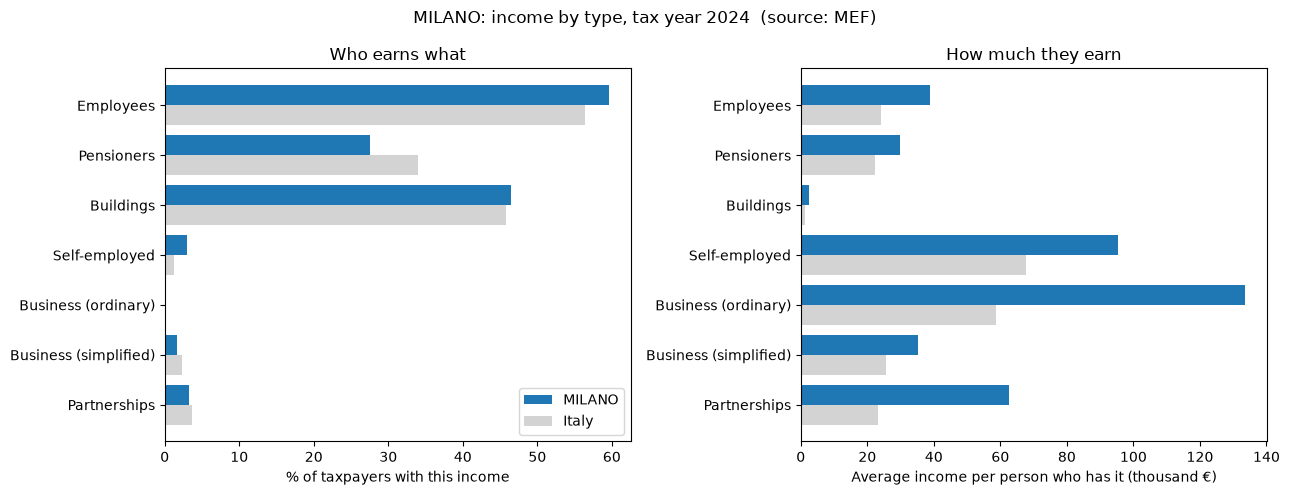

In [16]:
plot_income_types(mef_dfs[2024], "MILANO")
plt.show()

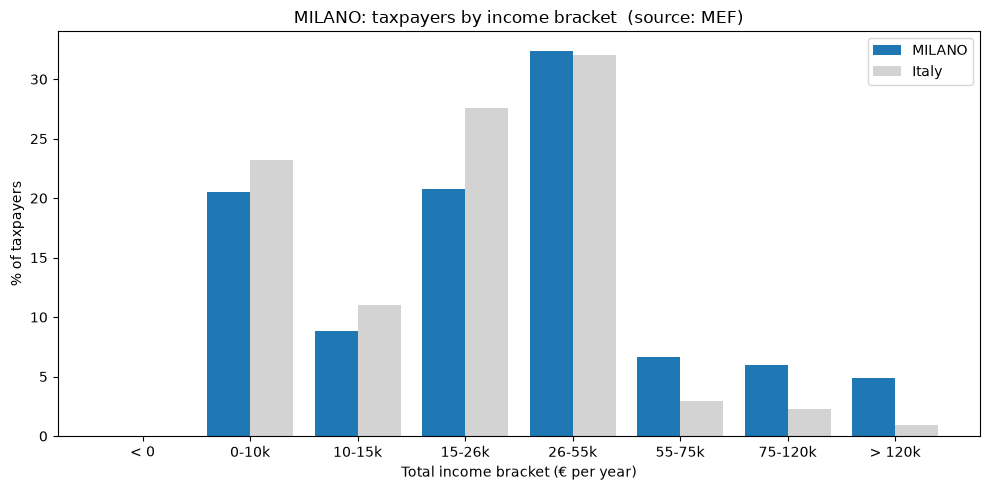

In [17]:
plot_income_brackets(mef_dfs[2024], "015146")
plt.show()

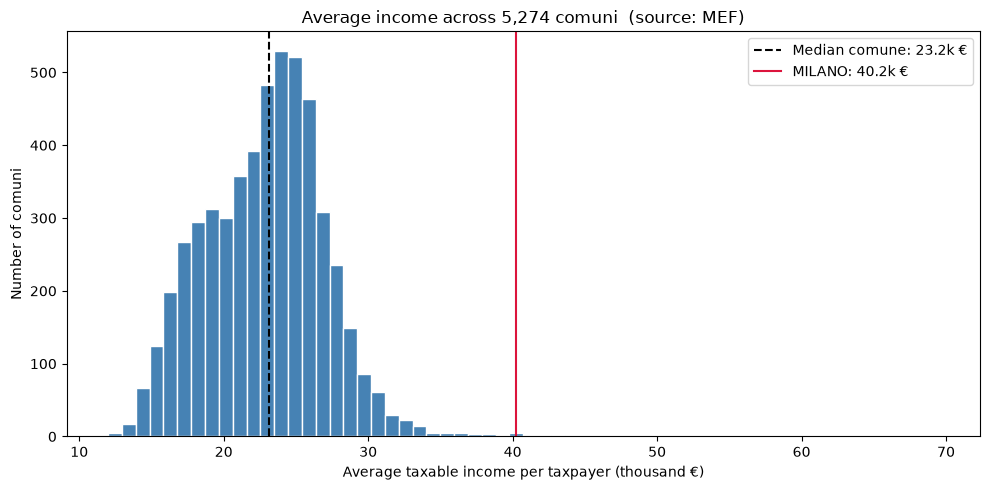

In [18]:
plot_mean_income_histogram(mef_dfs[2024], highlight="MILANO", min_taxpayers=1000)
plt.show()

Ideas to look at with these charts:
- Compare a rich city (Milano), a southern city (Napoli) and a mountain village.
- Where is the pensioner share much higher than in Italy?
- Does the 2014 histogram look shifted compared with 2024? (Remember: nominal euros.)

#### What the charts show

- to be completed

## 5. Three economic insights from the MEF data

1. **Income inequality**: Gini coefficient and top-income share per comune
2. **Effective tax rate**: how much IRPEF people really pay on their income
3. **Income mix 2014 → 2024**: did income from buildings (rents) grow compared
    with wages and business income?

Note: MEF data is about **income**, not wealth. A Gini on these brackets measures
*income* inequality. Wealth (houses, savings) is not in this data.

In [19]:
MIN_TAXPAYERS = 1000   # rankings only for comuni with at least this many taxpayers
 
# Brackets in increasing order of income. The negative bracket is left out:
# a Lorenz curve needs incomes >= 0.
POSITIVE_BRACKETS = {label: kw for label, kw in INCOME_BRACKETS.items() if label != "< 0"}

### 5.1 Income inequality

**Gini coefficient**: 0 = everyone has the same income, 1 = one person has
everything. We only know how many people are in each bracket and their total
income, so we draw the **Lorenz curve** through the bracket points and measure
the area between it and the line of perfect equality:

$$G = 1 - \sum_k (X_k - X_{k-1})(Y_k + Y_{k-1})$$

where $X_k$ = cumulative share of taxpayers and $Y_k$ = cumulative share of income
up to bracket $k$. Inequality *inside* each bracket is ignored, so this Gini is a
**lower bound** of the true value.

**Top-income share**: share of all income that goes to taxpayers above €75,000.

In [20]:
def bracket_matrix(df, kind):
    """
    Put the bracket values of every comune in one 2-D numpy array.
 
    Parameters
    ----------
    df : pandas.DataFrame
        A cleaned MEF table.
    kind : str
        ``"Frequenza"`` (taxpayers) or ``"Ammontare"`` (euros).
 
    Returns
    -------
    numpy.ndarray
        Shape (number of comuni, number of brackets), brackets in increasing
        order. Hidden values (NaN) are counted as 0.
    """
    columns = [find_column(df, kw, kind) for kw in POSITIVE_BRACKETS.values()]
    return df[columns].fillna(0).to_numpy(dtype=float)
 
 
def lorenz_points(freq, amount):
    """
    Cumulative shares of taxpayers (X) and of income (Y), starting from 0.
 
    Parameters
    ----------
    freq, amount : numpy.ndarray
        Arrays of shape (n_comuni, n_brackets) from ``bracket_matrix``.
 
    Returns
    -------
    tuple of numpy.ndarray
        ``(X, Y)``, each of shape (n_comuni, n_brackets + 1).
    """
    # keepdims=True keeps the shape (n, 1), so the division is done row by row
    # (numpy broadcasting)
    pop_share = freq / freq.sum(axis=1, keepdims=True)
    income_share = amount / amount.sum(axis=1, keepdims=True)
 
    zeros = np.zeros((freq.shape[0], 1))
    x = np.hstack([zeros, np.cumsum(pop_share, axis=1)])
    y = np.hstack([zeros, np.cumsum(income_share, axis=1)])
    return x, y
 
 
def gini_from_brackets(df):
    """
    Gini coefficient of income for every comune, from the MEF income brackets.
 
    Parameters
    ----------
    df : pandas.DataFrame
        A cleaned MEF table.
 
    Returns
    -------
    pandas.Series
        One Gini value (between 0 and 1) per row of ``df``.
    """
    x, y = lorenz_points(bracket_matrix(df, "Frequenza"), bracket_matrix(df, "Ammontare"))
    # np.diff gives X_k - X_{k-1}; y[:, 1:] + y[:, :-1] gives Y_k + Y_{k-1}
    gini = 1 - np.sum(np.diff(x, axis=1) * (y[:, 1:] + y[:, :-1]), axis=1)
    return pd.Series(gini, index=df.index)
 
 
def top_income_share(df, top_labels=("75-120k", "> 120k")):
    """
    Share of total income that goes to the top brackets.
 
    Parameters
    ----------
    df : pandas.DataFrame
        A cleaned MEF table.
    top_labels : tuple of str, optional
        The bracket labels that count as "top" (default: above €75,000).
 
    Returns
    -------
    pandas.Series
        A share between 0 and 1 for every row of ``df``.
    """
    amount = bracket_matrix(df, "Ammontare")
    labels = list(POSITIVE_BRACKETS)
    top_positions = [labels.index(label) for label in top_labels]
    return pd.Series(amount[:, top_positions].sum(axis=1) / amount.sum(axis=1), index=df.index)


In [21]:
for year, df in mef_dfs.items():
    df["gini"] = gini_from_brackets(df)
    df["top_share"] = top_income_share(df)
 
    # Italy as a whole: add up all comuni first, then compute (one row)
    italy = df[[col for col in df.columns if "Reddito complessivo" in col]].sum().to_frame().T
    italy_gini = gini_from_brackets(italy).iloc[0]
    italy_top = top_income_share(italy).iloc[0]
 
    big = df[df[TAXPAYERS_COL] >= MIN_TAXPAYERS]
    print(f"===== {year} =====")
    print(f"Italy: Gini = {italy_gini:.3f}, top share (>75k) = {italy_top:.1%}")
    print(big[["gini", "top_share"]].describe().round(3))
    print("\nMost unequal comuni:")
    print(big.nlargest(10, "gini")[[NAME_COL, TAXPAYERS_COL, "mean_income", "gini", "top_share"]])
    print()


===== 2014 =====
Italy: Gini = 0.427, top share (>75k) = 13.7%
           gini  top_share
count  5337.000   5337.000
mean      0.384      0.079
std       0.037      0.054
min       0.234      0.000
25%       0.358      0.040
50%       0.381      0.071
75%       0.407      0.105
max       0.632      0.536

Most unequal comuni:
                          Denominazione Comune  Numero contribuenti  \
3450                                  LAJATICO                 1003   
1618  CASTELBELLO CIARDES .KASTELBELL TSCHARS.                 3121   
6571                                   SANZENO                 1289   
2905                           FORTE DEI MARMI                 5486   
6826                     SILANDRO .SCHLANDERS.                 6639   
3486                               LASA .LAAS.                 4681   
3439                            LACES .LATSCH.                 6268   
570                                   BASIGLIO                 5257   
3618                             

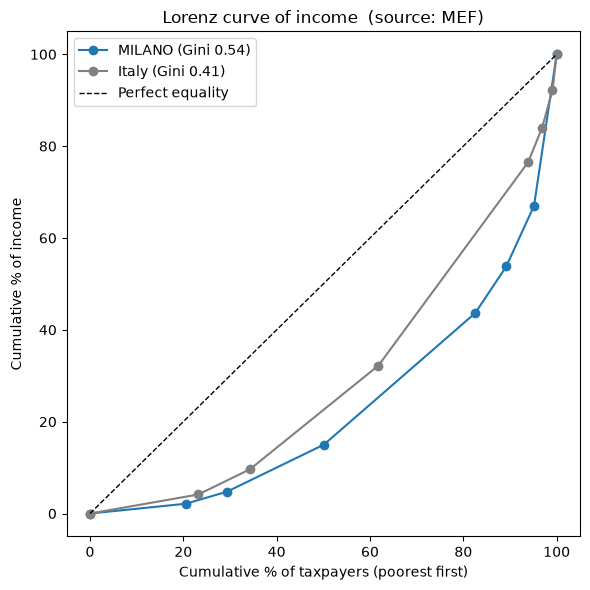

In [22]:
def plot_lorenz(df, comune):
    """
    Lorenz curve of one comune compared with Italy.
 
    Parameters
    ----------
    df : pandas.DataFrame
        A cleaned MEF table for one year (all comuni).
    comune : str
        ISTAT code or name of the comune.
 
    Returns
    -------
    matplotlib.figure.Figure
    """
    row = comune_row(df, comune)
    italy = df[[col for col in df.columns if "Reddito complessivo" in col]].sum().to_frame().T
 
    fig, ax = plt.subplots(figsize=(6, 6))
    for data, label, color in [(row, row[NAME_COL].iloc[0], "tab:blue"), (italy, "Italy", "gray")]:
        x, y = lorenz_points(bracket_matrix(data, "Frequenza"), bracket_matrix(data, "Ammontare"))
        gini = gini_from_brackets(data).iloc[0]
        ax.plot(x[0] * 100, y[0] * 100, marker="o", color=color, label=f"{label} (Gini {gini:.2f})")
    ax.plot([0, 100], [0, 100], "k--", linewidth=1, label="Perfect equality")
    ax.set_xlabel("Cumulative % of taxpayers (poorest first)")
    ax.set_ylabel("Cumulative % of income")
    ax.set_title("Lorenz curve of income  (source: MEF)")
    ax.legend()
    fig.tight_layout()
    return fig
 
 
plot_lorenz(mef_dfs[2024], "MILANO")
plt.show()

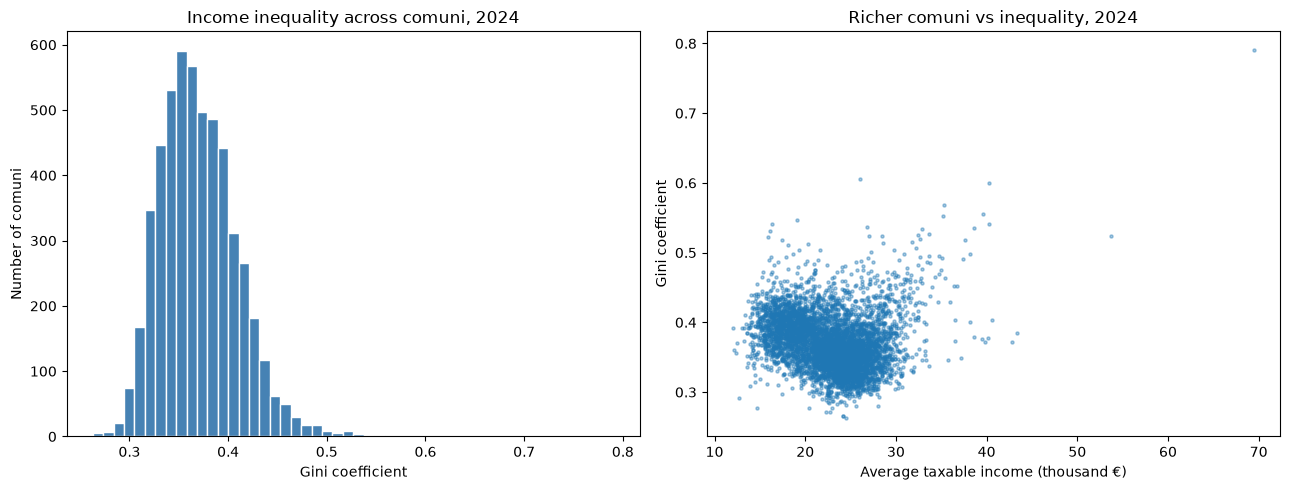

In [23]:
# Is inequality higher in richer comuni?
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
big = mef_dfs[2024][mef_dfs[2024][TAXPAYERS_COL] >= MIN_TAXPAYERS]
 
axes[0].hist(big["gini"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_xlabel("Gini coefficient")
axes[0].set_ylabel("Number of comuni")
axes[0].set_title("Income inequality across comuni, 2024")
 
axes[1].scatter(big["mean_income"] / 1000, big["gini"], s=5, alpha=0.4)
axes[1].set_xlabel("Average taxable income (thousand €)")
axes[1].set_ylabel("Gini coefficient")
axes[1].set_title("Richer comuni vs inequality, 2024")
fig.tight_layout()
plt.show()


#### What the inequality numbers show
- **Italy**: Gini 0.427 in 2014 and 0.407 in 2024; the top-income share (above 75k €) rose from 13.7% to 16.0%.
  These two look contradictory: the brackets are fixed in **nominal** euros, so inflation pushes people into higher brackets, and the flat-tax reform removed many self-employed incomes. Compare years with care.
- **Most unequal comuni** are of three kinds:
  - rich resorts and lake towns: Forte dei Marmi, Courmayeur, Cernobbio, Capalbio;
  - comuni where one or a few very high incomes dominate: Lajatico (about 1,000 taxpayers, Gini 0.79, mean income 69k €). In a small place, a handful of very high incomes is enough to push both the mean and the Gini up;
  - farming valleys of South Tyrol and Trentino (Val Venosta, Val di Non: Lasa, Silandro, Castelbello): low average income but high Gini, because farm income is taxed on fixed cadastral values and looks very small.
- **Milan** is among the most unequal large comuni (Gini 0.54).

### 5.2 Effective tax rate

The **average effective IRPEF rate** = tax actually paid / taxable income.
- *Imposta netta*: national IRPEF after tax credits (detrazioni)
- *Addizionali*: the extra regional and municipal income taxes

IRPEF is **progressive** (higher incomes pay a higher %), so richer comuni should
have higher rates. Between 2014 and 2024 two forces pushed in opposite directions:
- **fiscal drag**: incomes grew with inflation and moved into higher brackets;
- **tax cuts**: the 2022 and 2024 IRPEF reforms reduced rates for middle incomes.

(In economics, *pressione fiscale* means all taxes / GDP. This is narrower: only
the income tax of individuals.)

In [24]:
def effective_tax_rate(df, include_surcharges=True):
    """
    Average effective income tax rate of every comune.
 
    Parameters
    ----------
    df : pandas.DataFrame
        A cleaned MEF table.
    include_surcharges : bool, optional
        If True (default), add the regional and municipal surcharges to the tax.
 
    Returns
    -------
    pandas.Series
        Tax paid divided by taxable income, between 0 and 1.
    """
    tax = df["Imposta netta - Ammontare"].fillna(0)
    if include_surcharges:
        # NaN in the municipal surcharge = the comune applies no surcharge -> 0
        tax = tax + df["Addizionale regionale dovuta - Ammontare"].fillna(0)
        tax = tax + df["Addizionale comunale dovuta - Ammontare"].fillna(0)
    return tax / df[TAXABLE_AMOUNT_COL]


2014: Italy, national IRPEF only = 19.4%
count    8048.000
mean        0.186
std         0.029
min         0.080
25%         0.166
50%         0.187
75%         0.205
max         0.339
Name: tax_rate, dtype: float64

2024: Italy, national IRPEF only = 19.5%
count    7896.000
mean        0.194
std         0.024
min         0.106
25%         0.178
50%         0.194
75%         0.209
max         0.397
Name: tax_rate, dtype: float64



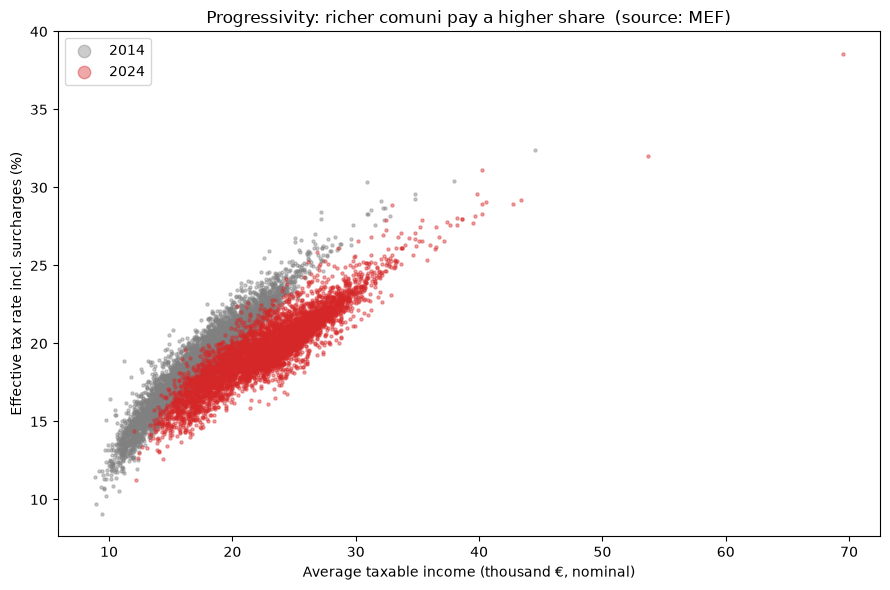

In [25]:
for year, df in mef_dfs.items():
    df["tax_rate"] = effective_tax_rate(df)
    italy_rate = df["Imposta netta - Ammontare"].sum() / df[TAXABLE_AMOUNT_COL].sum()
    print(f"{year}: Italy, national IRPEF only = {italy_rate:.1%}")
    print(df["tax_rate"].describe().round(3))
    print()
 
fig, ax = plt.subplots(figsize=(9, 6))
for year, color in [(2014, "gray"), (2024, "tab:red")]:
    big = mef_dfs[year][mef_dfs[year][TAXPAYERS_COL] >= MIN_TAXPAYERS]
    ax.scatter(big["mean_income"] / 1000, big["tax_rate"] * 100, s=5, alpha=0.4,
               color=color, label=str(year))
ax.set_xlabel("Average taxable income (thousand €, nominal)")
ax.set_ylabel("Effective tax rate incl. surcharges (%)")
ax.set_title("Progressivity: richer comuni pay a higher share  (source: MEF)")
ax.legend(markerscale=4)
fig.tight_layout()
plt.show()
 
# Question to answer: at the SAME income level, is the 2024 cloud above or below
# the 2014 one? Below = tax cuts won; above = fiscal drag won.


#### What the effective tax rate shows
- Nationally, net IRPEF was **19.4% of taxable income in 2014 and 19.5% in 2024**, even though nominal incomes grew by about 30%.
- With a progressive tax, inflation alone would have raised the rate (**fiscal drag**). It stayed flat because the 2022 and 2024 reforms cut rates for middle incomes: the two forces roughly cancelled out.
- The scatter shows the progressivity: richer comuni pay a higher share.

### 5.3 Income mix 2014 → 2024: buildings vs wages vs business

⚠️ **What this data can and cannot say.** MEF gives totals per comune, not the
same people over time. So we **cannot** see a person moving from a job to living
on rents. We **can** see whether the *mix* changed: the share of taxpayers with
each type of income, and the share of all income coming from each type.

⚠️ **Tax rules change the numbers.** Most rents today are taxed with the
*cedolare secca* (a flat tax on rents, also used for short-term rentals), and
empty second homes pay IMU instead of IRPEF. This income is largely **outside**
"Reddito da fabbricati". So a fall in building income can mean "landlords
switched to the flat tax", not "fewer people live on rents". Say this clearly.

In [26]:
def income_mix(df):
    """
    Share of taxpayers with each type of income, and share of total income from it.
 
    Parameters
    ----------
    df : pandas.DataFrame
        A cleaned MEF table (all comuni, or a subset).
 
    Returns
    -------
    pandas.DataFrame
        Index = income types; columns ``pct_taxpayers`` (people with that income /
        all taxpayers) and ``pct_income`` (euros of that type / euros of all types).
    """
    table = category_table(df, INCOME_TYPES)
    return pd.DataFrame({
        "pct_taxpayers": table["taxpayers"] / df[TAXPAYERS_COL].sum() * 100,
        "pct_income": table["amount"] / table["amount"].sum() * 100,
    })
 
 
mix = pd.concat({year: income_mix(df) for year, df in mef_dfs.items()}, axis=1)
mix[("change", "pct_taxpayers")] = mix[(2024, "pct_taxpayers")] - mix[(2014, "pct_taxpayers")]
mix[("change", "pct_income")] = mix[(2024, "pct_income")] - mix[(2014, "pct_income")]
print("Italy, income mix (%), change in percentage points:")
print(mix.round(1))


Italy, income mix (%), change in percentage points:
                               2014                     2024             \
                      pct_taxpayers pct_income pct_taxpayers pct_income   
Employees                      50.3       52.8          56.4       56.3   
Pensioners                     36.4       31.1          33.9       31.3   
Buildings                      45.9        3.8          45.8        2.6   
Self-employed                   2.3        4.1           1.2        3.3   
Business (ordinary)             0.4        0.6           0.2        0.5   
Business (simplified)           4.1        3.5           2.3        2.5   
Partnerships                    5.1        4.2           3.6        3.5   

                             change             
                      pct_taxpayers pct_income  
Employees                       6.1        3.6  
Pensioners                     -2.4        0.2  
Buildings                      -0.1       -1.2  
Self-employed              

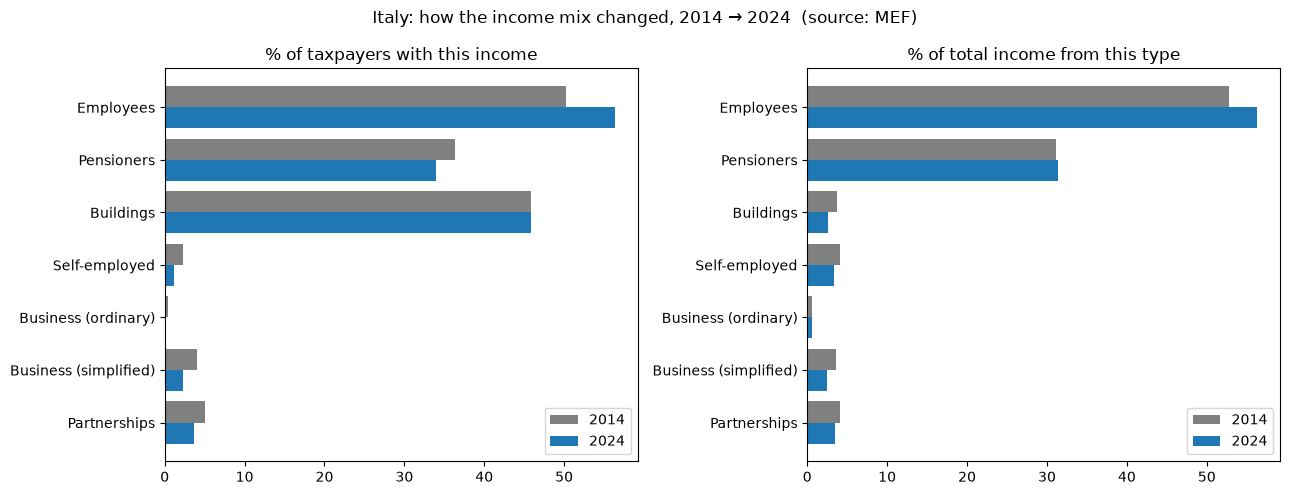

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
positions = np.arange(len(INCOME_TYPES))
for ax, column, title in [
    (axes[0], "pct_taxpayers", "% of taxpayers with this income"),
    (axes[1], "pct_income", "% of total income from this type"),
]:
    ax.barh(positions - 0.2, mix[(2014, column)], 0.4, label="2014", color="gray")
    ax.barh(positions + 0.2, mix[(2024, column)], 0.4, label="2024", color="tab:blue")
    ax.set_yticks(positions, INCOME_TYPES.keys())
    ax.invert_yaxis()
    ax.set_title(title)
    ax.legend()
fig.suptitle("Italy: how the income mix changed, 2014 → 2024  (source: MEF)")
fig.tight_layout()
plt.show()

#### What the national income mix shows
- **Buildings: ~46% of taxpayers but only ~3% of income.** The cadastral income of the main home is declared and then deducted, so this mostly counts **homeowners**, not landlords.
- **Self-employed, business and partnership income roughly halved.** Not because people stopped working on their own: the flat-tax regime (*forfettario*) was extended (up to 65k € in 2019, 85k € in 2023), so that income left IRPEF.
- **Employees grew from 50% to 56% of taxpayers**: record employment in 2023-24, plus the mechanical effect of self-employed people leaving the data.
- **Employees + pensioners = ~87% of the income IRPEF covers**: IRPEF has become mainly a tax on wages and pensions.

#### Per comune: where did building income gain weight?
Only comuni that exist in both years can be compared (merged comuni are lost
until the code harmonisation in Week 3).

Comuni in both years: 7647 (lost because merged: 401)
Excluded (size changed too much): ['ALAGNA VALSESIA', 'MONCENISIO', 'SAN FERMO DELLA BATTAGLIA', 'MAPPANO']
count    5095.00
mean       -0.95
std         0.47
min        -3.67
25%        -1.21
50%        -0.90
75%        -0.65
max         5.70
Name: change_pp, dtype: float64

Biggest increase of building income share (percentage points):
     Denominazione Comune_2024  building_share_2014  building_share_2024  \
1128         CAMPIONE D'ITALIA                0.060                0.117   
3745                      MASI                0.024                0.040   
5953     SAN GREGORIO D'IPPONA                0.008                0.014   
550             BASSANO ROMANO                0.029                0.034   
3157                 GROTTERIA                0.011                0.015   
197                     AMALFI                0.055                0.058   
30                  ACQUAPPESA                0.017                0.020  

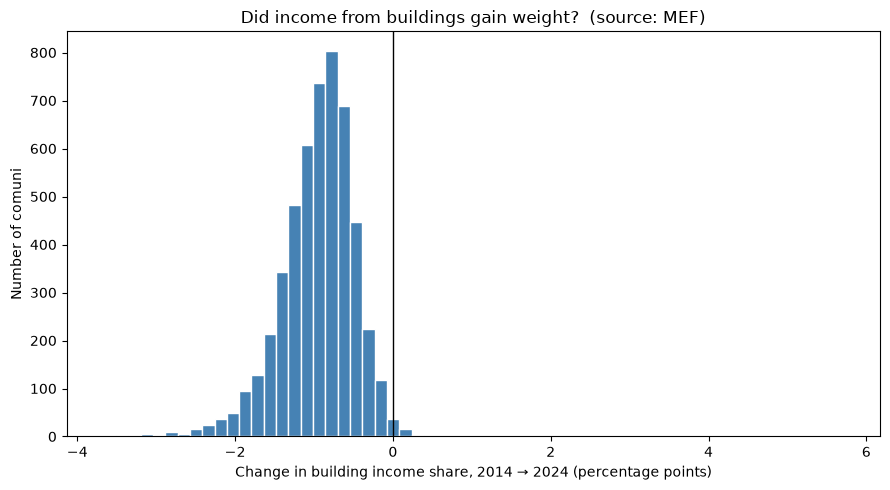

In [28]:
def building_share(df):
    """
    Share of all income (of the 7 types) that comes from buildings, per comune.
 
    Parameters
    ----------
    df : pandas.DataFrame
        A cleaned MEF table.
 
    Returns
    -------
    pandas.Series
        A share between 0 and 1 per row of ``df``.
    """
    amounts = pd.DataFrame({
        label: df[find_column(df, kw, "Ammontare")].fillna(0)
        for label, kw in INCOME_TYPES.items()
    })
    return amounts["Buildings"] / amounts.sum(axis=1)
 
 
columns = [CODE_COL, NAME_COL, TAXPAYERS_COL, "building_share"]
for year, df in mef_dfs.items():
    df["building_share"] = building_share(df)
 
both = mef_dfs[2014][columns].merge(
    mef_dfs[2024][columns], on=CODE_COL, suffixes=("_2014", "_2024"), validate="one_to_one"
)
print(f"Comuni in both years: {len(both)} (lost because merged: {len(mef_dfs[2014]) - len(both)})")

# Same code but not the same place: drop comuni whose number of taxpayers changed
# by more than 50% (e.g. Mappano: 12 taxpayers in 2014, 5,460 in 2024)
size_ratio = both[f"{TAXPAYERS_COL}_2024"] / both[f"{TAXPAYERS_COL}_2014"]
comparable = size_ratio.between(0.5, 1.5)
print("Excluded (size changed too much):", both.loc[~comparable, f"{NAME_COL}_2024"].tolist())
both = both[comparable]
 
both["change_pp"] = (both["building_share_2024"] - both["building_share_2014"]) * 100
big = both[both[f"{TAXPAYERS_COL}_2024"] >= MIN_TAXPAYERS]
print(big["change_pp"].describe().round(2))
print("\nBiggest increase of building income share (percentage points):")
print(big.nlargest(15, "change_pp")[[f"{NAME_COL}_2024", "building_share_2014", "building_share_2024", "change_pp"]].round(3))
 
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(big["change_pp"], bins=60, color="steelblue", edgecolor="white")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Change in building income share, 2014 → 2024 (percentage points)")
ax.set_ylabel("Number of comuni")
ax.set_title("Did income from buildings gain weight?  (source: MEF)")
fig.tight_layout()
plt.show()
 
# Look at the names in the top 15: tourist towns? University cities? Mountain
# resorts? That pattern is the insight; the cedolare secca caveat is the limitation.

In [29]:
# Comuni where the building income share went UP between 2014 and 2024.
# No size filter here: we want to see them all, but we flag the small ones.
risers = both[both["change_pp"] > 0].sort_values("change_pp", ascending=False).copy()
risers["small"] = risers[f"{TAXPAYERS_COL}_2024"] < MIN_TAXPAYERS

print(f"{len(risers)} of {len(both)} comuni saw the building share rise "
      f"({risers['small'].sum()} of them have fewer than {MIN_TAXPAYERS} taxpayers)")

columns_to_show = [
    f"{NAME_COL}_2024", f"{TAXPAYERS_COL}_2024",
    "building_share_2014", "building_share_2024", "change_pp", "small",
]
# to_string() prints every column in full, without the "..." pandas uses for wide tables
print(risers[columns_to_show].head(30).round(3).to_string())

275 of 7643 comuni saw the building share rise (237 of them have fewer than 1000 taxpayers)
            Denominazione Comune_2024  Numero contribuenti_2024  building_share_2014  building_share_2024  change_pp  small
1932                         CERVATTO                        37                0.048                0.114      6.676   True
1128                CAMPIONE D'ITALIA                      1499                0.060                0.117      5.705  False
581                         BELGIRATE                       382                0.065                0.105      4.054   True
4912                        PONTBOSET                       147                0.018                0.058      4.029   True
7438  VILLA SANTA LUCIA DEGLI ABRUZZI                        76                0.017                0.054      3.652   True
7269                         VERNAZZA                       606                0.074                0.107      3.262   True
4549                             ONZO   

#### What the risers tell us
- Most comuni where the building share rose are **tiny villages** (fewer than 1,000 taxpayers): mostly noise.
- **Tourist towns**: Vernazza (Cinque Terre), Castelmola (Taormina), Belgirate and Brienno (lakes), Avelengo and Cibiana di Cadore (Alps, Dolomites).
- **Denominator effect**: Campione d'Italia's casino, the main employer, went bankrupt in 2018. Wages collapsed, so building income weighs more even without new rents.
- Overall: building income fell almost everywhere because of national tax rules; the exceptions are tourist towns and places where other incomes collapsed.

#### Checking two suspicious rows
The search below found where the odd rows came from:
- the row named `0` (2024, 5,305 taxpayers) was the last row of the file, with taxpayers not assigned to any comune. It is removed by the 6-digit code filter, so it no longer appears;
- **Mappano** (`001316`) was created in 2013 but became operational only in 2017: its 2014 row covers only 12 taxpayers, so it is excluded from the 2014 -> 2024 comparison by the size filter.

In [30]:
for year, df in mef_dfs.items():
    mask = (df[NAME_COL].astype(str) == "0") | (df[NAME_COL] == "MAPPANO")
    print(year)
    print(df.loc[mask, [CODE_COL, NAME_COL, PROVINCE_COL, TAXPAYERS_COL]].to_string())

2014
     Codice Istat Comune Denominazione Comune Sigla Provincia  Numero contribuenti
8015              001316              MAPPANO              TO                   12
2024
     Codice Istat Comune Denominazione Comune Sigla Provincia  Numero contribuenti
7774              001316              MAPPANO              TO                 5460
